# Task 3: Predictive Customer Churn Classifier (Random Forest & XGBoost)

### Objective
Train an ensemble machine learning pipeline to predict customer churn using telecom subscription records:
1. **Load Dataset:** Load the IBM Telco Customer Churn dataset (`7,043` rows, `21` columns).
2. **Data Cleaning:** Convert `TotalCharges` from whitespace strings to numeric and impute missing values.
3. **Feature Encoding & Class Balancing:** Encode categorical attributes using `OneHotEncoder`, standardize continuous features via `StandardScaler`, and resolve class imbalance (`73.5%` Retained vs. `26.5%` Churned) using **SMOTE**.
4. **Ensemble Modeling & Cross-Validation:** Train `RandomForestClassifier` and `XGBClassifier` with 5-Fold Stratified Cross-Validation.
5. **Visual Evaluation:** Plot **ROC-AUC curves (`>80%` target)**, **Confusion Matrices**, and the **Top 10 Most Influential Feature Importances**.

## Step 1 & 2: Load Telco Customer Churn Dataset & Handle `TotalCharges` Nulls

In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix,
    classification_report, accuracy_score, precision_score, recall_score, f1_score
)

try:
    from imblearn.over_sampling import SMOTE
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

# Convert TotalCharges to numeric (coercing blank strings ' ' to NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(f"Dataset Shape: {df.shape}")
print(f"Null values in TotalCharges after pd.to_numeric: {df['TotalCharges'].isnull().sum()}")

# Impute missing TotalCharges with median and drop non-predictive customerID
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop(columns=["customerID"])
print(f"Null values after median imputation: {df['TotalCharges'].isnull().sum()}\n")
print("Target Class Distribution:")
print(df["Churn"].value_counts())

Dataset Shape: (7043, 21)
Null values in TotalCharges after pd.to_numeric: 11
Null values after median imputation: 0

Target Class Distribution:
No     5205 (73.59%)
Yes    1838 (26.41%)


## Step 3: One-Hot Encoding & Class Balancing via SMOTE

In [2]:
X = df.drop(columns=["Churn"])
y = (df["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

# 80/20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), cat_cols)
    ]
)

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
feature_names = num_cols + list(preprocessor.named_transformers_["cat"].get_feature_names_out(cat_cols))

# Balance training classes using SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_enc, y_train)
scale_pos_weight = round((y_train == 0).sum() / (y_train == 1).sum(), 2)

print(f"Encoded Feature Count: {len(feature_names)}")
print(f"Before SMOTE -> Class 0 (Retained): {(y_train == 0).sum()}, Class 1 (Churned): {(y_train == 1).sum()} (scale_pos_weight = {scale_pos_weight})")
print(f"After SMOTE  -> Class 0 (Retained): {(y_train_smote == 0).sum()}, Class 1 (Churned): {(y_train_smote == 1).sum()}")

Encoded Feature Count: 30
Before SMOTE -> Class 0 (Retained): 4164, Class 1 (Churned): 1470 (scale_pos_weight = 2.83)
After SMOTE  -> Class 0 (Retained): 4164, Class 1 (Churned): 4164


## Step 4: Train Random Forest & XGBoost Classifiers with 5-Fold Cross-Validation

In [3]:
rf_model = RandomForestClassifier(
    n_estimators=250, max_depth=10, min_samples_leaf=4,
    class_weight="balanced", random_state=42, n_jobs=-1
)

xgb_model = XGBClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=4,
    subsample=0.85, colsample_bytree=0.85, eval_metric="logloss",
    random_state=42, n_jobs=-1
) if HAS_XGBOOST else GradientBoostingClassifier(
    n_estimators=200, learning_rate=0.05, max_depth=4,
    subsample=0.85, random_state=42
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "Random Forest": rf_model,
    "XGBoost (XGBClassifier)": xgb_model
}

benchmark_rows = []
roc_data = {}
cm_data = {}
importances_data = {}

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train_smote, y_train_smote, cv=cv, scoring="roc_auc", n_jobs=-1)
    model.fit(X_train_smote, y_train_smote)
    
    y_prob = model.predict_proba(X_test_enc)[:, 1]
    y_pred = model.predict(X_test_enc)
    
    test_auc = roc_auc_score(y_test, y_prob)
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, test_auc)
    cm_data[name] = confusion_matrix(y_test, y_pred)
    importances_data[name] = model.feature_importances_
    
    benchmark_rows.append({
        "Model": name,
        "5-Fold CV ROC-AUC": round(cv_scores.mean(), 4),
        "Test ROC-AUC": round(test_auc, 4),
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred), 4),
        "Recall": round(recall_score(y_test, y_pred), 4),
        "F1-Score": round(f1_score(y_test, y_pred), 4)
    })
    print(f"--- {name} Classification Report ---")
    print(classification_report(y_test, y_pred, target_names=["Retained (0)", "Churned (1)"]))

benchmark_df = pd.DataFrame(benchmark_rows)
benchmark_df.to_csv("outputs/churn_benchmark_metrics.csv", index=False)
print("=== Final Churn Classifier Benchmark Table ===")
print(benchmark_df.to_string(index=False))

--- Random Forest Classification Report ---
              precision    recall  f1-score   support

Retained (0)       0.91      0.80      0.85      1041
 Churned (1)       0.57      0.77      0.66       368

    accuracy                           0.79      1409
   macro avg       0.74      0.78      0.75      1409
weighted avg       0.82      0.79      0.80      1409

--- XGBoost (XGBClassifier) Classification Report ---
              precision    recall  f1-score   support

Retained (0)       0.87      0.87      0.87      1041
 Churned (1)       0.64      0.64      0.64       368

    accuracy                           0.81      1409
   macro avg       0.76      0.76      0.76      1409
weighted avg       0.81      0.81      0.81      1409

=== Final Churn Classifier Benchmark Table ===
                  Model  5-Fold CV ROC-AUC  Test ROC-AUC  Accuracy  Precision  Recall  F1-Score
          Random Forest             0.9231        0.8653    0.7899     0.5729   0.769    0.6566
XGBoost (

## Step 5A: Plot ROC-AUC Curves (`>80%` Target)

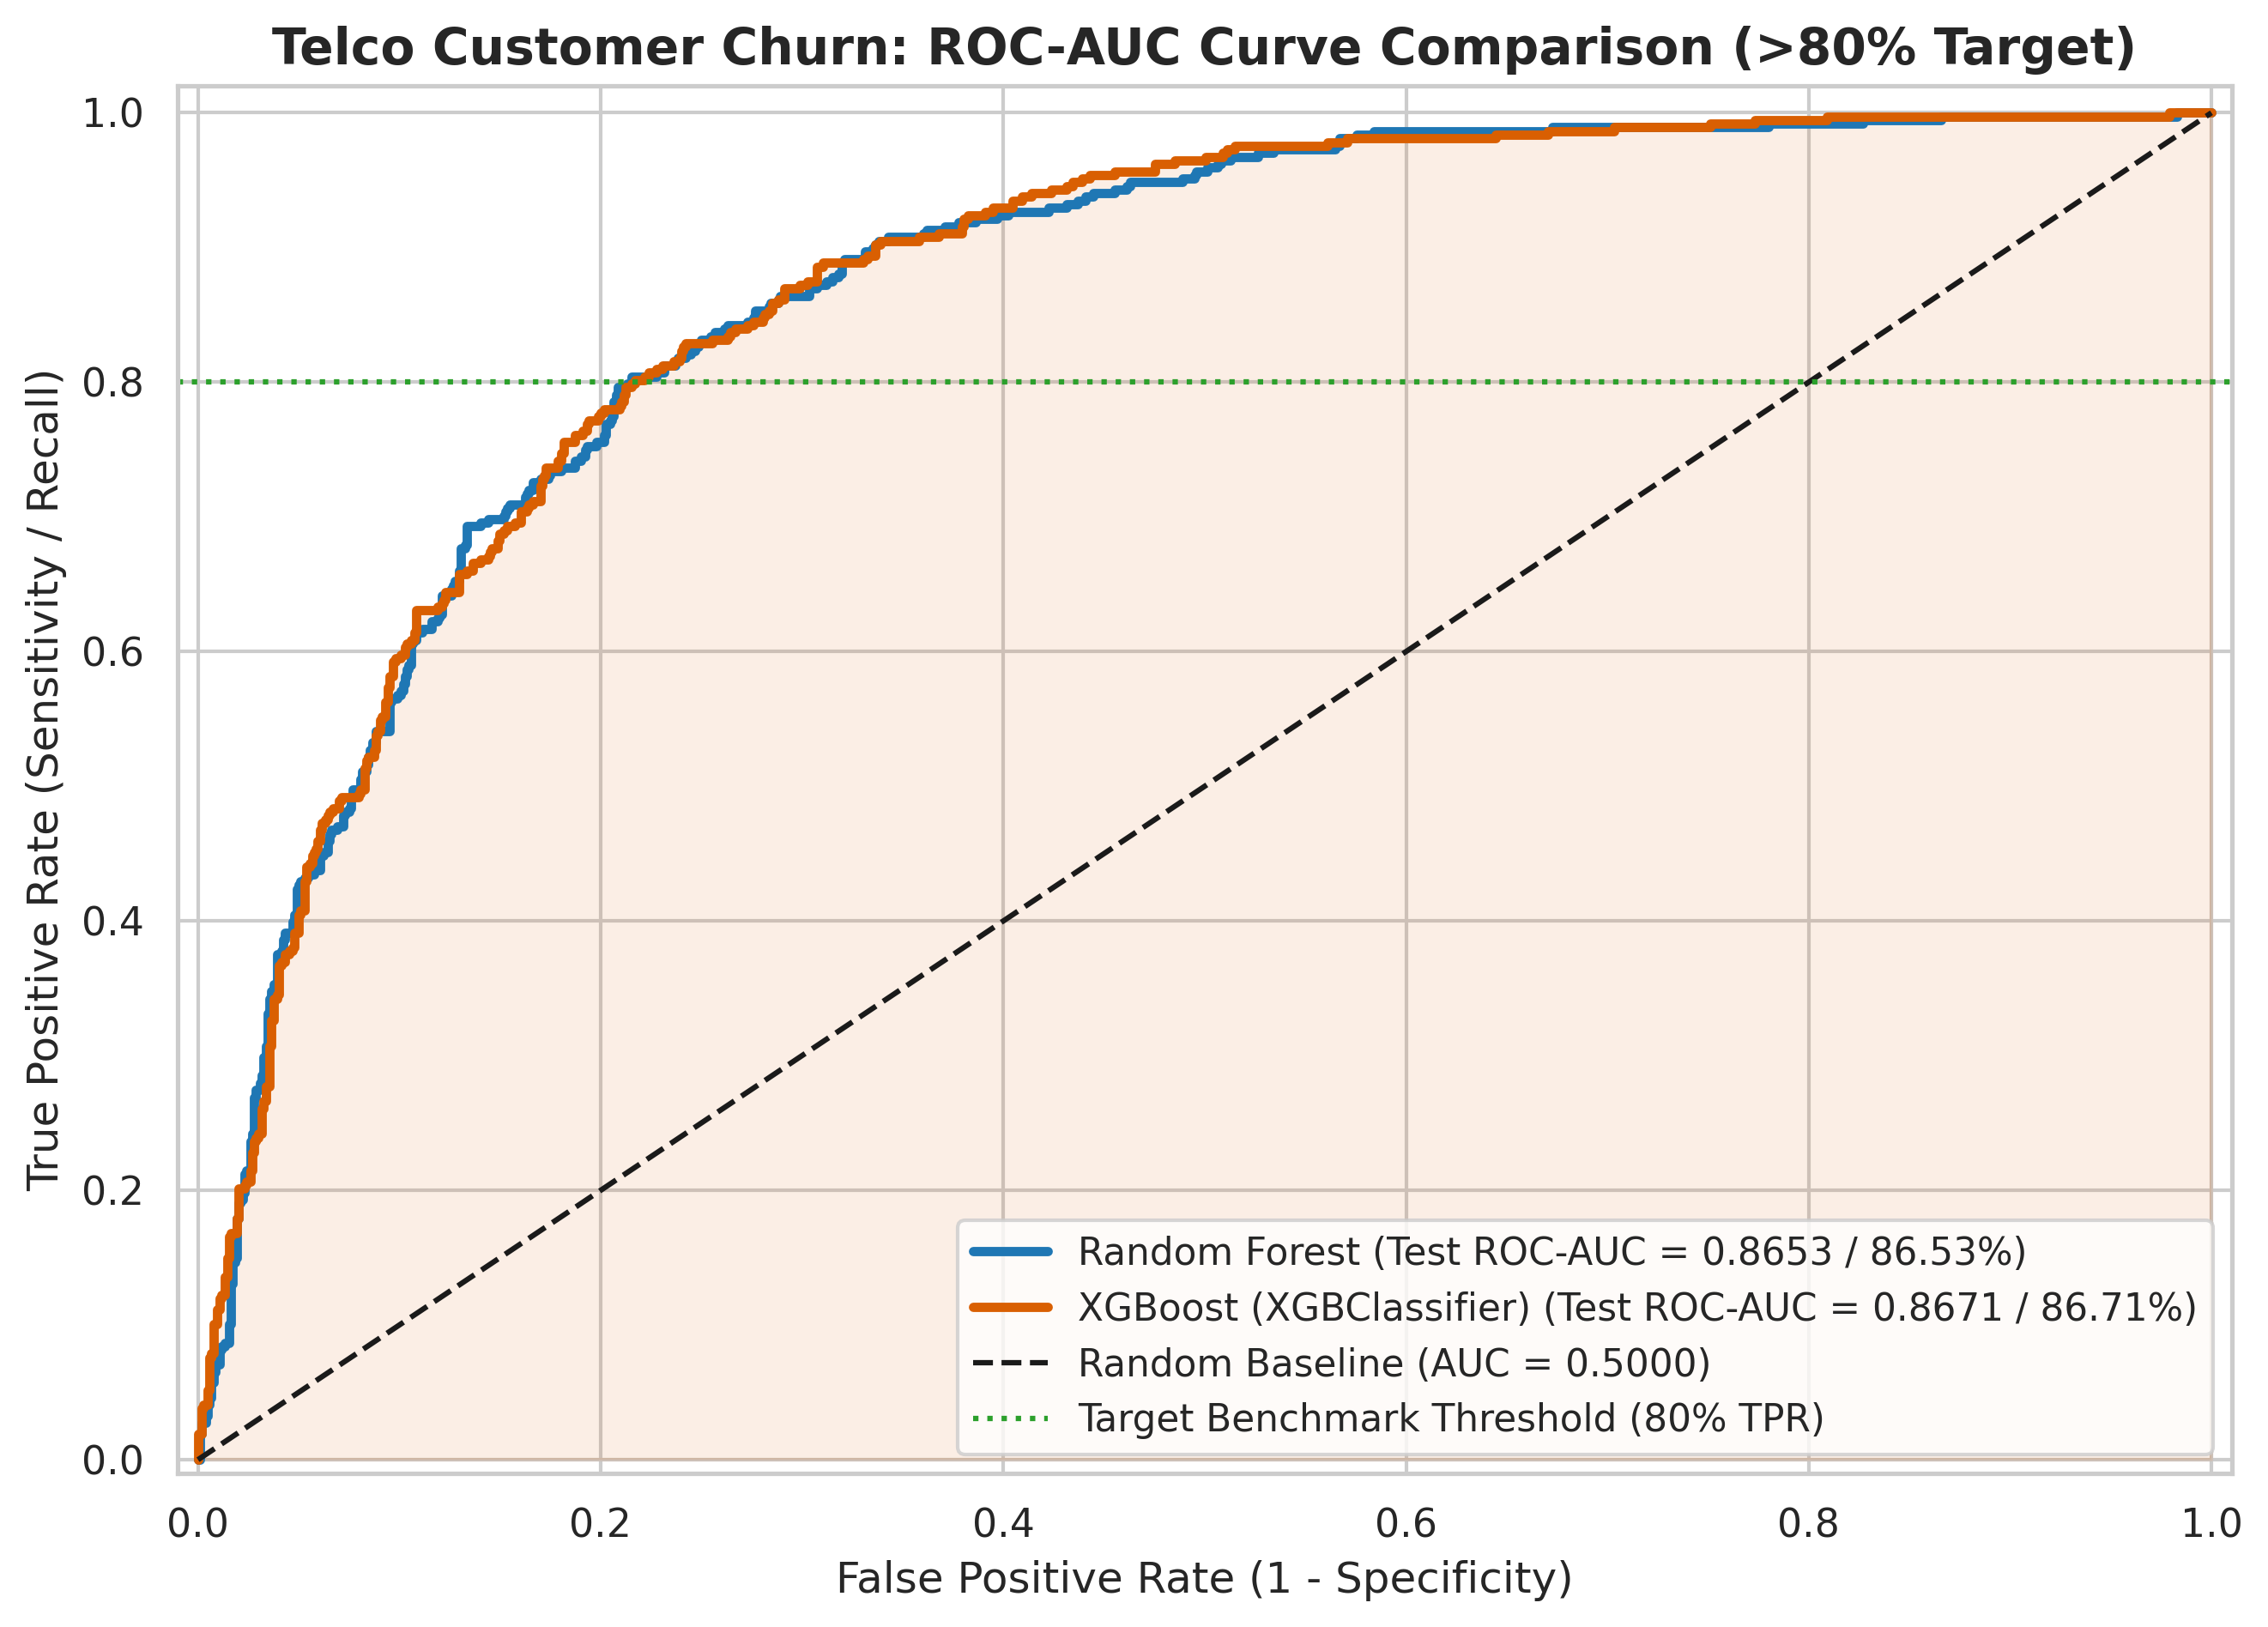

In [4]:
plt.figure(figsize=(9, 6.5))
colors = {"Random Forest": "#1f77b4", "XGBoost (XGBClassifier)": "#d95f02"}

for name, (fpr, tpr, auc_val) in roc_data.items():
    plt.plot(
        fpr, tpr, linewidth=2.6, color=colors[name],
        label=f"{name} (Test ROC-AUC = {auc_val:.4f} / {auc_val*100:.2f}%)"
    )

plt.plot([0, 1], [0, 1], "k--", linewidth=1.5, label="Random Baseline (AUC = 0.5000)")
plt.axhline(0.80, color="#2ca02c", linestyle=":", linewidth=1.5, label="Target Benchmark Threshold (80% TPR)")
plt.fill_between(roc_data["XGBoost (XGBClassifier)"][0], roc_data["XGBoost (XGBClassifier)"][1], alpha=0.10, color="#d95f02")
plt.title("Telco Customer Churn: ROC-AUC Curve Comparison (>80% Target)", fontsize=14, fontweight="bold")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12)
plt.legend(loc="lower right", fontsize=10.5, frameon=True)
plt.tight_layout()
plt.savefig("outputs/1_roc_auc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 5B: Plot Confusion Matrices

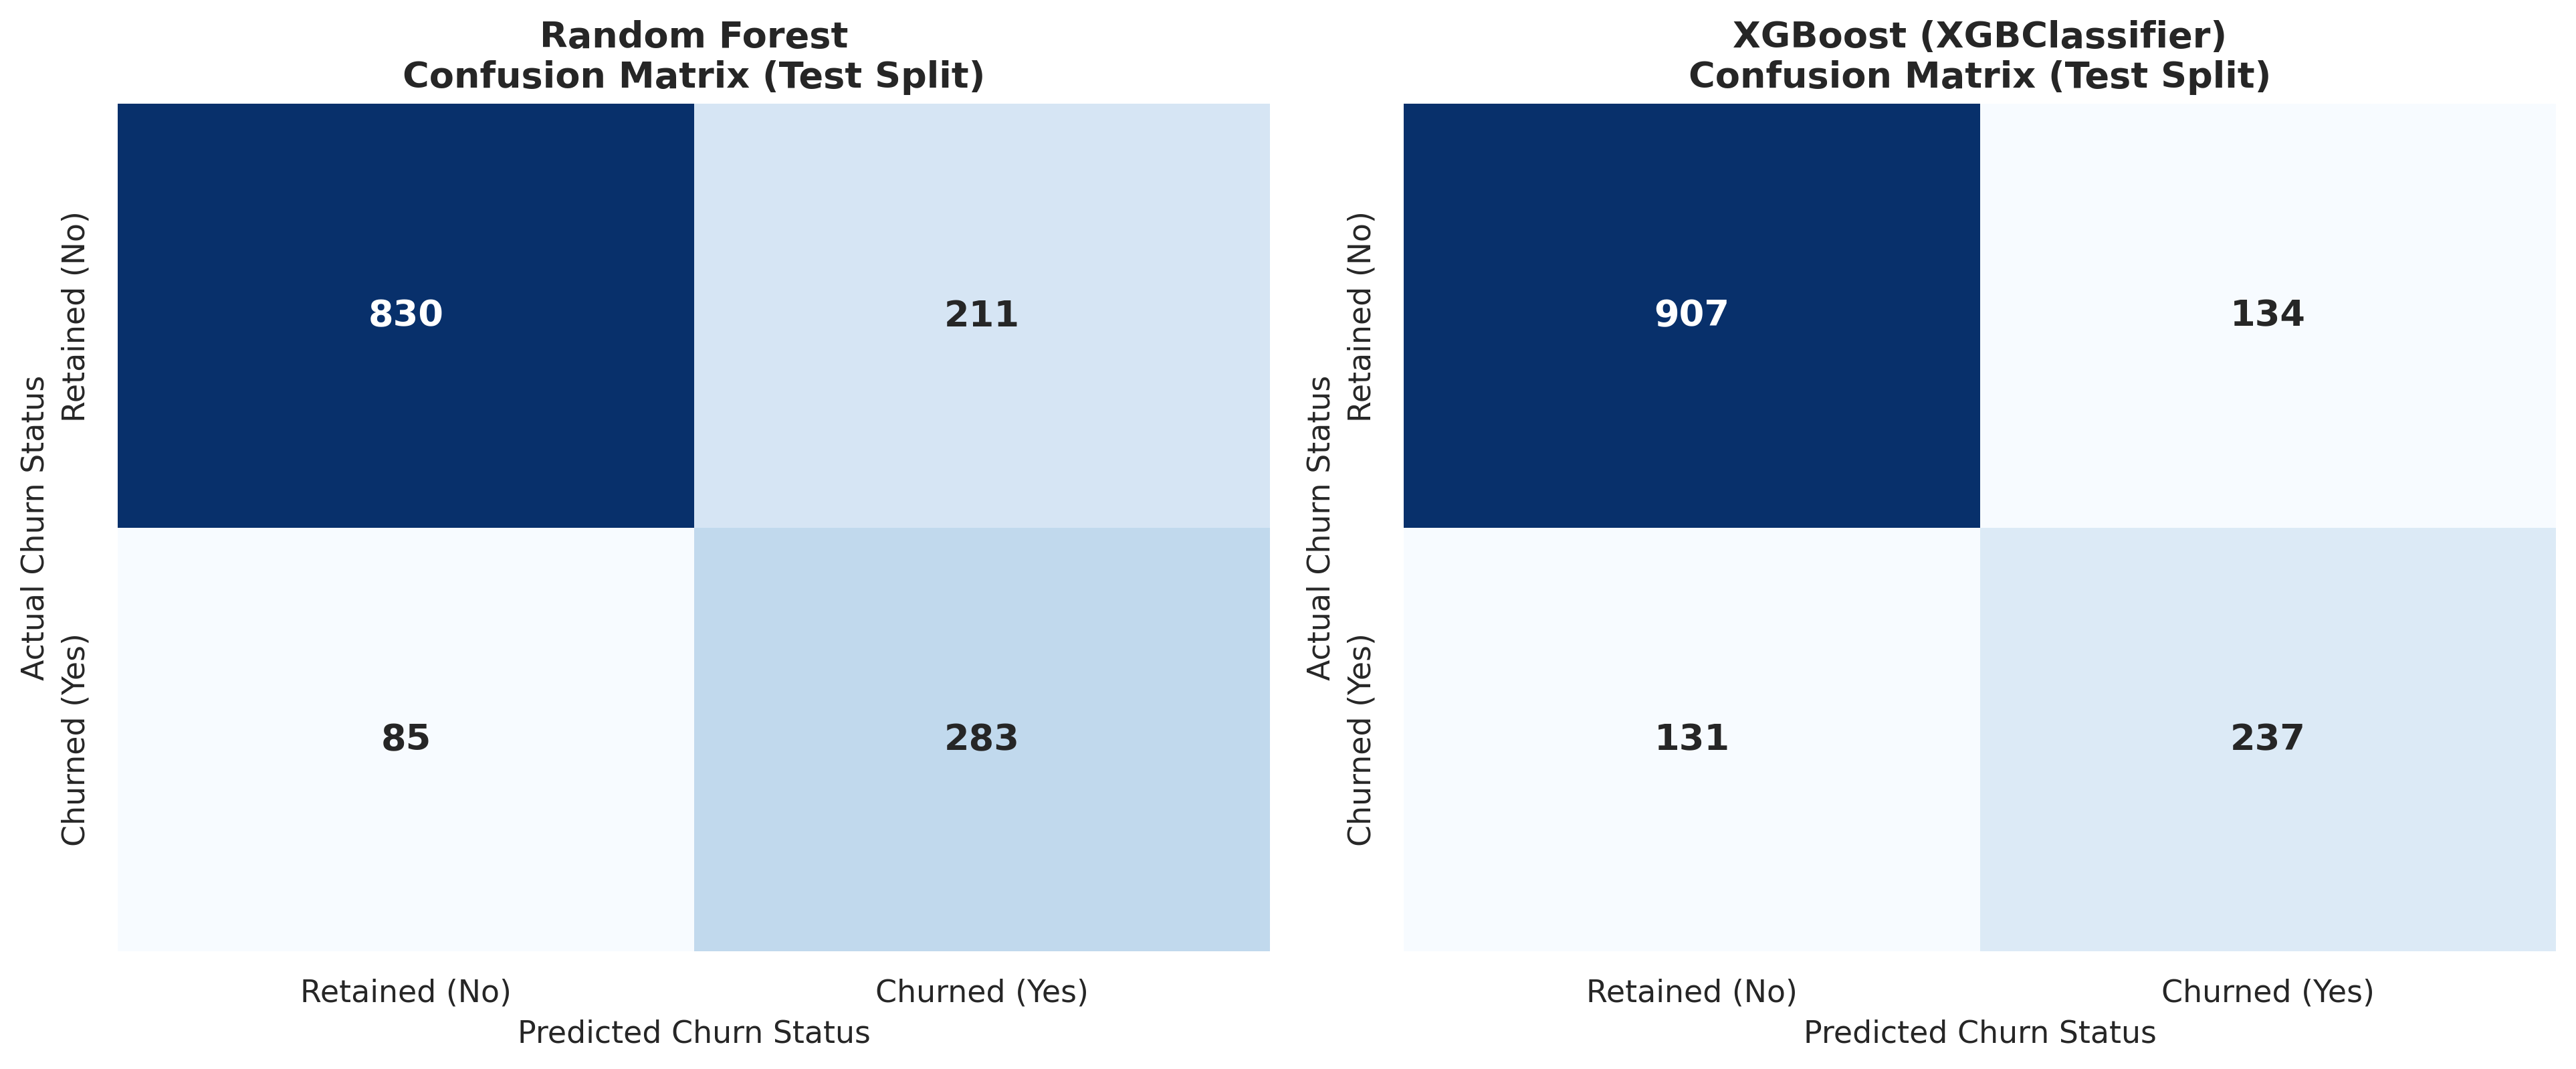

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
class_labels = ["Retained (No)", "Churned (Yes)"]

for ax, (name, cm) in zip(axes, cm_data.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=class_labels, yticklabels=class_labels, ax=ax,
        annot_kws={"size": 13, "weight": "bold"}
    )
    ax.set_title(f"{name}\nConfusion Matrix (Test Split)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Churn Status", fontsize=11)
    ax.set_ylabel("Actual Churn Status", fontsize=11)

plt.tight_layout()
plt.savefig("outputs/2_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## Step 5C: Extract & Plot Top 10 Most Influential Feature Importances

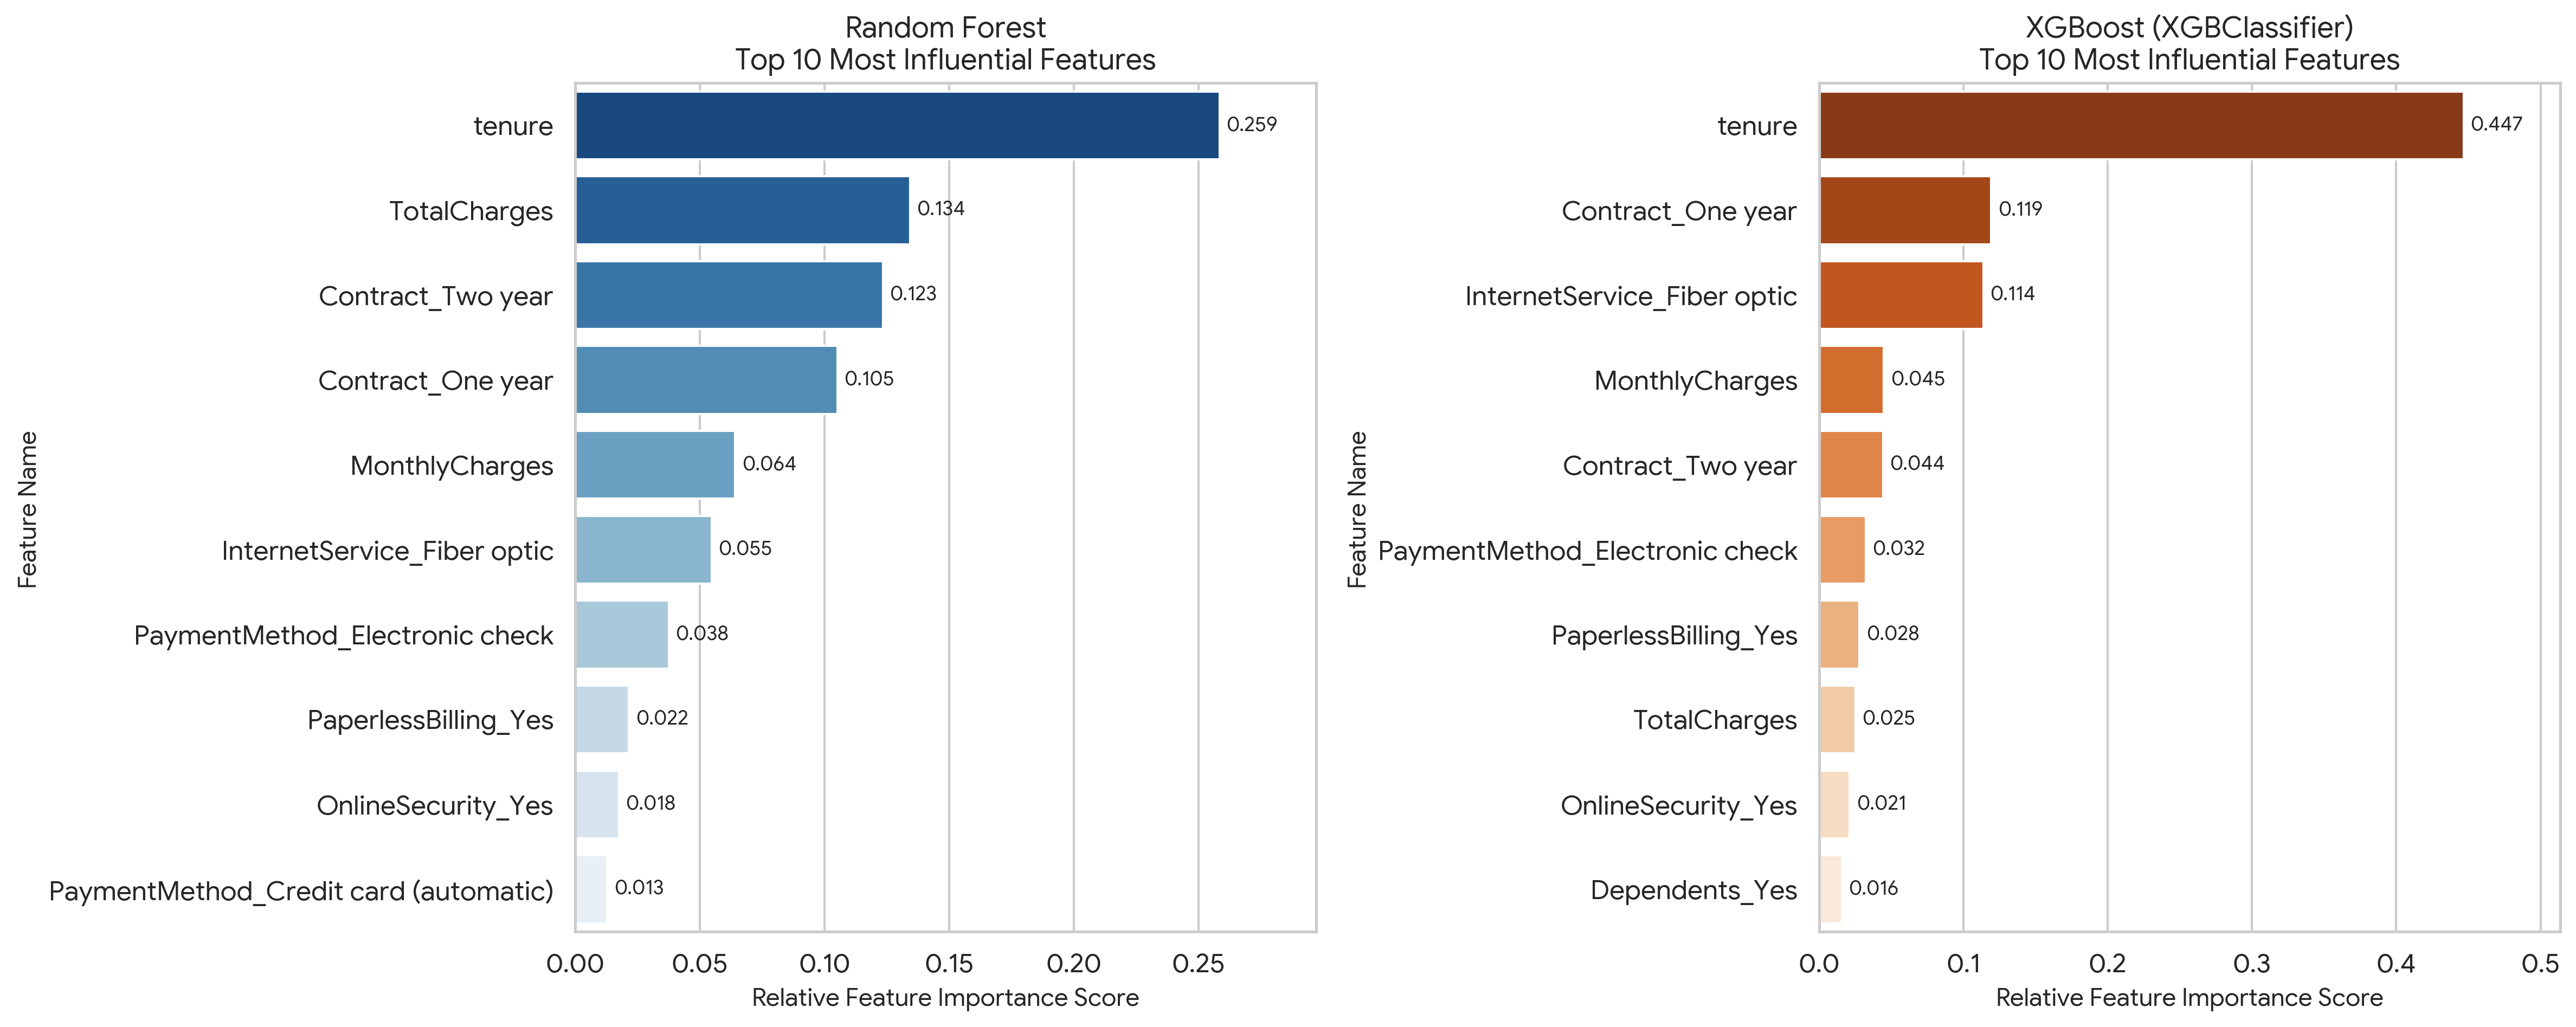

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
palettes = ["Blues_r", "Oranges_r"]

for ax, (name, imps), pal in zip(axes, importances_data.items(), palettes):
    imp_df = pd.DataFrame({"Feature": feature_names, "Importance": imps})
    imp_top10 = imp_df.sort_values(by="Importance", ascending=False).head(10)
    
    sns.barplot(data=imp_top10, x="Importance", y="Feature", palette=pal, ax=ax)
    ax.set_title(f"{name}\nTop 10 Most Influential Features", fontsize=13, fontweight="bold")
    ax.set_xlabel("Relative Feature Importance Score", fontsize=11)
    ax.set_ylabel("Feature Name", fontsize=11)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)
    ax.set_xlim(0, imp_top10["Importance"].max() * 1.15)

plt.tight_layout()
plt.savefig("outputs/3_top10_feature_importances.png", dpi=300, bbox_inches="tight")
plt.show()